<a href="https://colab.research.google.com/github/cikicali369-glitch/DSB-Unit-03/blob/main/labs/01%20-%20Regression-Sacramento/lab-regression-sacramento-YOURNAME-HERE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<img src="https://github.com/cikicali369-glitch/DSB-Unit-03/blob/main/labs/01%20-%20Regression-Sacramento/assets/ga-logo.png?raw=1" style="float: left; margin: 20px; height: 55px">

# Lab: Simple Linear Regression with Sacramento Real Estate Data

---

In this lab you will hone your exploratory data analysis (EDA) skills and practice constructing linear regressions on a data set of Sacramento real estate sales.  The data set contains information on qualities of the property, location of the property, and time of sale.

Ali Cikic

### 1. Read in the Sacramento housing data set.

The file is stored in the `data` subfolder.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#  URL
url = 'https://raw.githubusercontent.com/cikicali369-glitch/DSB-Unit-03/main/labs/01%20-%20Regression-Sacramento/data/sacramento_real_estate_transactions.csv'

df = pd.read_csv(url)
df.head()

,street,city,zip,state,beds,baths,sq__ft,type,sale_date,price,latitude,longitude
0,3526 HIGH ST,SACRAMENTO,95838,CA,2,1,836,Residential,Wed May 21 00:00:00 EDT 2008,59222,38.631913,-121.434879
1,51 OMAHA CT,SACRAMENTO,95823,CA,3,1,1167,Residential,Wed May 21 00:00:00 EDT 2008,68212,38.478902,-121.431028
2,2796 BRANCH ST,SACRAMENTO,95815,CA,2,1,796,Residential,Wed May 21 00:00:00 EDT 2008,68880,38.618305,-121.443839
3,2805 JANETTE WAY,SACRAMENTO,95815,CA,2,1,852,Residential,Wed May 21 00:00:00 EDT 2008,69307,38.616835,-121.439146
4,6001 MCMAHON DR,SACRAMENTO,95824,CA,2,1,797,Residential,Wed May 21 00:00:00 EDT 2008,81900,38.519470,-121.435768


### 2. Conduct exploratory data analysis on this data set.

If you discover any issues with the data, fix them to the best of your ability. Report any notable findings.

_**Note:** Zip codes often have leading zeros — e.g., 02215 = Boston, MA — which will often get knocked off automatically by many software programs like Python or Excel._

In [3]:
# 1. Pregled osnovnih informacija i tipova podataka
print("--- INFO O PODACIMA ---")
print(df.info())

# 2. Provjera da li imamo nedostajućih (null) vrijednosti
print("\n--- NEDOSTAJUĆE VRIJEDNOSTI ---")
print(df.isnull().sum())

# 3. Kreiramo folder datasets ako ne postoji i snimamo fajl
import os
os.makedirs('./datasets', exist_ok=True)

df.to_csv('./datasets/sacramento_cleaned_dataframe.csv', index=False)
print("\nUspješno sačuvano u './datasets/sacramento_cleaned_dataframe.csv'!")

--- INFO O PODACIMA ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 985 entries, 0 to 984
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   street     985 non-null    object 
 1   city       985 non-null    object 
 2   zip        985 non-null    int64  
 3   state      985 non-null    object 
 4   beds       985 non-null    int64  
 5   baths      985 non-null    int64  
 6   sq__ft     985 non-null    int64  
 7   type       985 non-null    object 
 8   sale_date  985 non-null    object 
 9   price      985 non-null    int64  
 10  latitude   985 non-null    float64
 11  longitude  985 non-null    float64
dtypes: float64(2), int64(5), object(5)
memory usage: 92.5+ KB
None

--- NEDOSTAJUĆE VRIJEDNOSTI ---
street       0
city         0
zip          0
state        0
beds         0
baths        0
sq__ft       0
type         0
sale_date    0
price        0
latitude     0
longitude    0
dtype: int64

Uspješno sačuvan

When you've finished cleaning or have made a good deal of progress cleaning, it's always a good idea to save your work. Use the pandas `to_csv` method to export your cleaned dataset.

```python
# example -- your dataframe name may be different
dataframe.to_csv('./datasets/sacramento_cleaned_dataframe.csv', index=False)

```

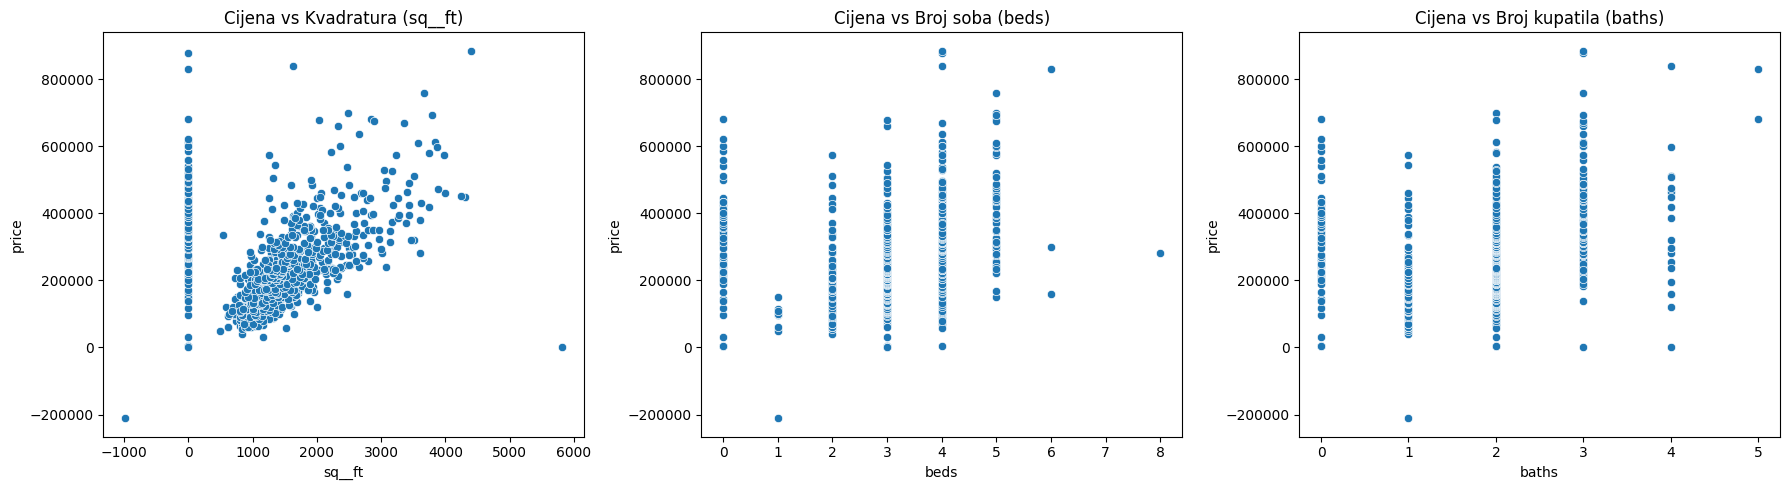

In [4]:
# Korak 3: Crtamo grafove za potencijalne prediktore cijene
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=df, x='sq__ft', y='price', ax=axes[0])
axes[0].set_title('Cijena vs Kvadratura (sq__ft)')

sns.scatterplot(data=df, x='beds', y='price', ax=axes[1])
axes[1].set_title('Cijena vs Broj soba (beds)')

sns.scatterplot(data=df, x='baths', y='price', ax=axes[2])
axes[2].set_title('Cijena vs Broj kupatila (baths)')

plt.tight_layout()
plt.show()

# Single Linear Regression Model (SLR)

### 3. Our goal will be to predict price. List variables that you think qualify as predictors of price in an SLR model.

For each of the variables you believe should be considered, generate a plot showing the relationship between the independent and dependent variables.

Potential predictors for price include `sq__ft` (square footage), `beds` (number of bedrooms), and `baths` (number of bathrooms). Their relationships with price are shown in the scatter plots above.

### 4. Which variable would be the best predictor of Y in an SLR model? Why?

`sq__ft` (square footage) is the best predictor of price in an SLR model.
Why? Because it shows a clear, positive linear trend with price and has a continuous distribution of values, whereas `beds` and `baths` are discrete integers that cluster data into vertical lines, making a linear fit less descriptive.

### 5. Using `scikit-learn` create a SLR and return the intercept and slope coefficients that minimize SSE.

#### SSE (Sum of Squared Errors)

SSE is just the total of all the squared prediction mistakes.

1. For each data point, figure out how far off your prediction was (actual minus predicted).
2. Square that number (to make negatives positive and punish big errors more).
3. Add them all up.

**Why it matters:** You were asked to find the slope and intercept that **minimize SSE**. That's literally what linear regression does — it searches for the line that makes this total as small as possible.

**Related terms:**
- **MSE** = SSE ÷ n (average of the squared errors)
- **RMSE** = √MSE (puts it back in original units)

So: **SSE → MSE → RMSE** is just the same number, adjusted differently for interpretation purposes.


-----

You may need to load in the scikit-learn API:

```python
from sklearn.linear_model import LinearRegression

model = LinearRegression()
```



In [5]:
from sklearn.linear_model import LinearRegression

# 1. Postavljamo naš prediktor (X) i ciljnu varijablu (y)
X = df[['sq__ft']]
y = df['price']

# 2. Inicijalizujemo i treniramo model linearne regresije
model = LinearRegression()
model.fit(X, y)

# 3. Ispisujemo dobijene koeficijente
print("Intercept (β0):", model.intercept_)
print("Slope (β1):", model.coef_[0])

Intercept (β0): 161272.75277922262
Slope (β1): 55.1772124050074


### 5 [bonus]. Write a function that will take in two lists, `x` and `y`, and return the intercept and slope coefficients that minimize SSE.

`y` is the target variable, and `x` is the predictor variable.

**Don't use `scikit-learn` for this**. Instead, use `numpy` and `scipy`.

The slope and intercept of simple linear regression can be calculated by using certain summary statistics. In particular, we'll need to know:

- $\bar{x}$, the mean of `x`
- $\bar{y}$, the mean of `y`
- $s_{x}$, the standard deviation of `x`
- $s_{y}$, the standard deviation of `y`
- $r_{xy}$, the correlation of `x` and `y`

Given these summary statistics, the **coefficient on `X`** (or the slope) can be given by $\beta_{1} = r_{xy} * \frac{s_{y}}{s_{x}}$. The **intercept of the model** can be given by $\beta_{0} = \bar{y} - \beta_{1}\bar{x}$.

Your function should take in `x` and `y`, then use the above summary statistics to calculate the slope and intercept.

- **Test your function on price and the variable you determined was the best predictor in Problem 4.**
- **Report the slope and intercept.**

In [6]:
import numpy as np

def calculate_slope_intercept(x, y):
    # 1. Srednje vrijednosti (means)
    x_bar = np.mean(x)
    y_bar = np.mean(y)

    # 2. Standardne devijacije (sa ddof=1 za uzorak)
    s_x = np.std(x, ddof=1)
    s_y = np.std(y, ddof=1)

    # 3. Korelacija između x i y
    r_xy = np.corrcoef(x, y)[0, 1]

    # 4. Izračunavanje nagiba (slope / beta_1)
    beta_1 = r_xy * (s_y / s_x)

    # 5. Izračunavanje presjeka (intercept / beta_0)
    beta_0 = y_bar - (beta_1 * x_bar)

    return beta_0, beta_1

# Testiramo funkciju na kvadraturi (sq__ft) i cijeni (price)
intercept, slope = calculate_slope_intercept(df['sq__ft'], df['price'])

print("Izračunati Intercept (β0):", intercept)
print("Izračunati Slope (β1):", slope)

Izračunati Intercept (β0): 161272.7527792226
Izračunati Slope (β1): 55.17721240500744


### 6. Interpret the intercept and the slope.

In your own words, write here what is the meaning of each one of those values
and how can they be helpful for you when predicting prices or interpreting the
predictions of your model.

Intercept ($\beta_0 \approx 161,272.75$): This represents the predicted base price of a home when the square footage is 0. While a house with 0 square feet is physically impossible, it acts as the mathematical starting point or baseline for our model.
Slope ($\beta_1 \approx 55.18$): This means that for every additional 1 square foot of area, the predicted price of the house increases on average by about $55.18.
They are helpful because we can use them to predict the price of a home just by knowing its size, and we can use them for inference to understand how strongly house size influences price.

### 7. Give an example of how this model could be used for prediction and how it could be used for inference.

**Be sure to make it clear which example is associated with prediction and which is associated with inference.**

Suppose we want to estimate the selling price of a new house that has 2,000 square feet. We plug $X = 2000$ into our model formula ($Price = 161,272.75 + 55.18 \times 2000$) to predict its expected price of approximately $271,632.75$.
Inference Example: Suppose a real estate agent wants to understand the market relationship between size and price. We use inference to conclude that for every 100 square feet added to a home, the price increases on average by $5,518, helping us understand how strongly size impacts market value.

### 8: [Bonus] Using the model you came up with in Part 5, calculate and plot the residuals.

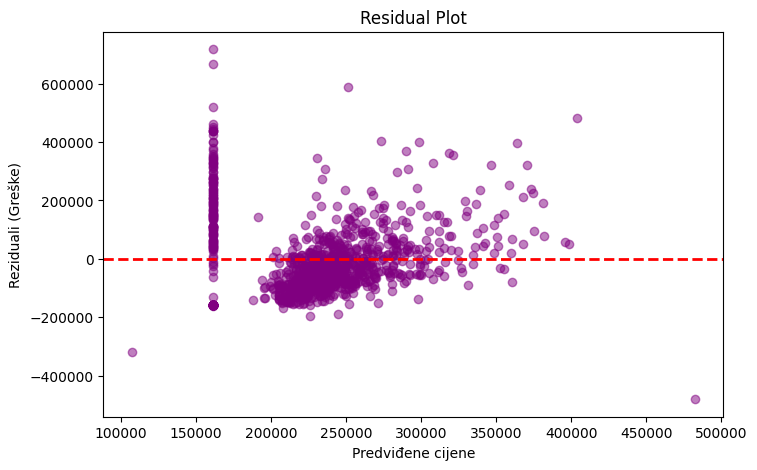

In [7]:
# Izračunavamo predikcije i reziduale
y_pred = model.predict(X)
residuals = y - y_pred

# Crtamo rezidualni plot
plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.5, color='purple')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Predviđene cijene')
plt.ylabel('Reziduali (Greške)')
plt.title('Residual Plot')
plt.show()

---

## Reminder about categorical variables and dummy variables

It is important to be cautious with categorical variables, which represent distict groups or categories, when building a regression. If put in a regression "as-is," categorical variables represented as integers will be treated like *continuous* variables.

That is to say, instead of group "3" having a different effect on the estimation than group "1" it will estimate literally 3 times more than group 1.

For example, if occupation category "1" represents "analyst" and occupation category "3" represents "barista", and our target variable is salary, if we leave this as a column of integers then barista will always have `beta*3` the effect of analyst.

This will almost certainly force the beta coefficient to be something strange and incorrect. Instead, we can re-represent the categories as multiple "dummy coded" columns.



#### A Word of Caution When Creating Dummies

Let's touch on precautions we should take when dummy coding.

**If you convert a qualitative variable to dummy variables, you want to turn a variable with N categories into N-1 variables.**

> **Scenario 1:** Suppose we're working with the variable "sex" or "gender" with values "M" and "F".

You should include in your model only one variable for "sex = F" which takes on 1 if sex is female and 0 if sex is not female! Rather than saying "a one unit change in X," the coefficient associated with "sex = F" is interpreted as the average change in Y when sex = F relative to when sex = M.

| Female | Male |
|-------|------|
| 0 | 1 |
| 1 | 0 |
| 0 | 1 |
| 1 | 0 |
| 1 | 0 |
_As we can see a 1 in the female column indicates a 0 in the male column. And so, we have two columns stating the same information in different ways._

> Scenario 2: Suppose we're modeling revenue at a bar for each of the days of the week. We have a column with strings identifying which day of the week this observation occured in.

We might include six of the days as their own variables: "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday". **But not all 7 days.**  

|Monday | Tuesday | Wednesday | Thursday | Friday | Saturday |
|-------|---------|-----------|----------|--------|----------|
| 1     | 0       |0          |      0   |0       | 0        |
| 0     | 1       |0          |      0   |0       | 0        |
| 0     | 0       |1          |      0   |0       | 0        |
| 0     | 0       |0          |      1   |0       | 0        |
| 0     | 0       |0          |      0   |1       | 0        |
| 0     | 0       |0          |      0   |0       | 1        |
| 0     | 0       |0          |      0   |0       | 0        |

_As humans we can infer from the last row that if its is not Monday, Tuesday, Wednesday, Thursday, Friday or Saturday, it must be Sunday. Models work the same way._

The coefficient for Monday is then interpreted as the average change in revenue when "day = Monday" relative to "day = Sunday." The coefficient for Tuesday is interpreted as the average change in revenue when "day = Tuesday" relative to "day = Sunday" and so on.

The category you leave out, which the other columns are *relative to*, is often referred to as the **reference category**.

### 9. Use the `pd.get_dummies` function to convert the `type` column into dummy-coded variables.

In [8]:
# Korak 9: Kreiramo dummy varijable za tip nekretnine
df = pd.get_dummies(df, columns=['type'], drop_first=True)

print("Dummy varijable su uspješno kreirane!")

Dummy varijable su uspješno kreirane!


### 10. Check the dummy columns you've created. Do they all make sense?

Use `.head()` on the new dataframe you've created. Depending on how you cleaned the data earlier in this notebook, there may be a dummy column that needs to be removed. Check that all the columns you've created make sense, and if any of the columns seem to be errors, drop them. If there don't appear to be any errors, then move on to the next step!

In [9]:
# Korak 10: Provjeravamo novouređeni dataframe sa dummy kolonama
df.head()

,street,city,zip,state,beds,baths,sq__ft,sale_date,price,latitude,longitude,type_Multi-Family,type_Residential,type_Unkown
0,3526 HIGH ST,SACRAMENTO,95838,CA,2,1,836,Wed May 21 00:00:00 EDT 2008,59222,38.631913,-121.434879,False,True,False
1,51 OMAHA CT,SACRAMENTO,95823,CA,3,1,1167,Wed May 21 00:00:00 EDT 2008,68212,38.478902,-121.431028,False,True,False
2,2796 BRANCH ST,SACRAMENTO,95815,CA,2,1,796,Wed May 21 00:00:00 EDT 2008,68880,38.618305,-121.443839,False,True,False
3,2805 JANETTE WAY,SACRAMENTO,95815,CA,2,1,852,Wed May 21 00:00:00 EDT 2008,69307,38.616835,-121.439146,False,True,False
4,6001 MCMAHON DR,SACRAMENTO,95824,CA,2,1,797,Wed May 21 00:00:00 EDT 2008,81900,38.519470,-121.435768,False,True,False


# Multivariate Linear Regression Model (MLR)

### 11. Build what you think may be the best MLR model predicting `price`.

Choose at least three variables, and build a model that uses them to predict price. At least one of the variables you choose should be a dummy-coded variable. (This can be one we created before or a new one.)

You may need to load in the scikit-learn API:

```python
from sklearn.linear_model import LinearRegression

model = LinearRegression()
```

In [10]:
from sklearn.linear_model import LinearRegression

# Definiramo naše tri varijable i ciljnu cijenu
features = ['sq__ft', 'beds', 'type_Residential']
X_mlr = df[features]
y = df['price']

# Treniramo multivarijatni model
mlr_model = LinearRegression()
mlr_model.fit(X_mlr, y)

print("Intercept:", mlr_model.intercept_)
for f, c in zip(features, mlr_model.coef_):
    print(f"Koeficijent za {f}: {c}")

Intercept: 83748.98484916106
Koeficijent za sq__ft: 31.518003106381332
Koeficijent za beds: 21018.105649671663
Koeficijent za type_Residential: 50902.57944718433


### 12. Plot the true price vs the predicted price to evaluate your MLR visually.

You can use matplotlib or seaborn, the choice is yours !

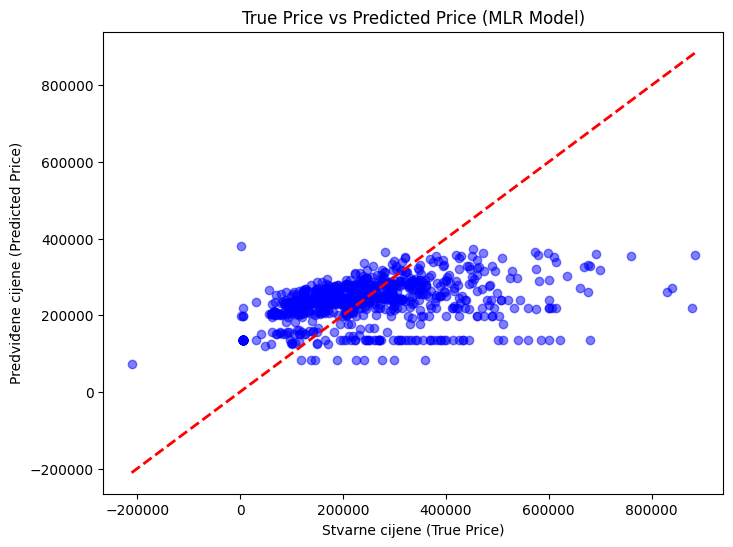

In [11]:
# 1. Izračunavamo predviđene cijene za MLR model
y_pred_mlr = mlr_model.predict(X_mlr)

# 2. Crtamo scatter plot: Stvarne vs Predviđene cijene
plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred_mlr, alpha=0.5, color='blue')

# Dodajemo idealnu liniju (gdje su stvarna i predviđena cijena iste)
plt.plot([y.min(), y.max()], [y.min(), y.max()], color='red', linestyle='--', linewidth=2)

plt.xlabel('Stvarne cijene (True Price)')
plt.ylabel('Predviđene cijene (Predicted Price)')
plt.title('True Price vs Predicted Price (MLR Model)')
plt.show()

### 13. List the five assumptions for an MLR model.

Indicate which ones are the same as the assumptions for an SLR model.

Here are the five assumptions for an MLR model, noting which ones are shared with SLR:

1. Linearity: The relationship between the predictors and the target variable is linear. (Same as SLR)
2. Independence: The residuals (errors) are independent of each other. (Same as SLR)
3. Homoscedasticity: The variance of the residuals is constant across all predicted values (no clear patterns or "funnel shapes" in the residual plot). (Same as SLR)
4. Normality: The residuals are normally distributed. (Same as SLR)
5. No Multicollinearity: The independent predictor variables are not excessively correlated with one another. (This one is unique to MLR, because SLR only has a single predictor).

### 14. Pick at least two assumptions and explain whether or not you believe them to be met for your model, and explain why.

1. Linearity: We believe this assumption is reasonably met. Based on our exploratory scatter plots, increases in square footage (`sq__ft`) lead to a general, proportional upward trend in price.
2. Homoscedasticity: This assumption is partially violated. In real estate data, larger and more expensive homes typically show a wider spread of prices (higher variance) than smaller homes, which is a common real-world pattern known as heteroscedasticity.

### 15. [Bonus - optional] Generate a table showing the point estimates, standard errors, t-scores, p-values, and 95% confidence intervals for the model you built.

**Write a few sentences interpreting some of the output.**

> **Hint:** scikit-learn does not have this functionality built in, but statsmodels does in the `summary` method.  To fit the statsmodels model use something like the following.  There is one big caveat here, however!  `statsmodels.OLS` does _not_ add an intercept to your model, so you will need to do this explicitly by adding a column filled with the number 1 to your X matrix

```python
import statsmodels.api as sm

# The Default here is Linear Regression (ordinary least squares regression OLS)
model = sm.OLS(y,X).fit()
```

In [12]:
import statsmodels.api as sm

# 1. Dodajemo intercept (konstantnu kolonu sa jedinicama) u našu X matricu
X_mlr_sm = sm.add_constant(X_mlr)

# 2. Kreiramo i fitujemo OLS model
ols_model = sm.OLS(y, X_mlr_sm).fit()

# 3. Prikazujemo tabelu sa rezultatima
ols_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  price   R-squared:                       0.147
Model:                            OLS   Adj. R-squared:                  0.145
Method:                 Least Squares   F-statistic:                     56.55
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           1.01e-33
Time:                        19:41:04   Log-Likelihood:                -12984.
No. Observations:                 985   AIC:                         2.598e+04
Df Residuals:                     981   BIC:                         2.600e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
====================================================================================
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
const             8.375e+04   1.71e+04      4.910      0.000    5.03e+04    1.17e+05
sq__ft              31.5180      6.574      4.794      0.000      18.617      44.419
beds              2.102e+04   4327.988      4.856      0.000    1.25e+04    2.95e+04
type_Residential   5.09e+04   1.64e+04      3.112      0.002    1.88e+04     8.3e+04
==============================================================================
Omnibus:                      265.675   Durbin-Watson:                   0.367
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              636.730
Skew:                           1.439   Prob(JB):                    5.44e-139
Kurtosis:                       5.689   Cond. No.                     8.60e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 8.6e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

Point Estimates (Coefficients): Show the expected change in price for a unit change in each predictor while holding all other variables constant.
- p-values: Tell us whether a predictor is statistically significant. A p-value below 0.05 indicates that the variable has a meaningful, statistically significant effect on the house price.
- Confidence Intervals (95% CI): Provide a range of values within which we are 95% confident the true population coefficient lies.

### 16. Metrics, metrics, everywhere...

Calculate and interpret at least three regression metrics. How well does your model perform?

## Metric Comparison Table

| Metric | What It Tells You | Punishes Big Mistakes? | Adjusts for Extra Inputs? | Examples of When to Use It |
|---|---|---|---|---|
| **R²** | What percent of the output's variation did the model explain? (0% to 100%) | Indirectly | ❌ No | • Pitching model quality in a presentation: "My model explains 73% of the price variation."<br>• Comparing two models on the same dataset.<br>• Quick sanity check: if R² is near zero, your inputs aren't helping. |
| **Adjusted R²** | Like R², but penalizes you for throwing in too many inputs | Indirectly | ✅ Yes | • You add/remove variables and want to know if performance truly improved.<br>• Deciding whether a new feature is worth keeping in production.<br>• Anytime you're comparing models with different numbers of predictors. |
| **MSE** | Average squared error. Lower is better. | ✅ Strongly (squared!) | ❌ No | • The loss function that regression algorithms optimize internally.<br>• Math-heavy contexts (calculus, derivation).<br>• Rarely reported to stakeholders — too abstract. |
| **RMSE** | On average, how far off are predictions (in original units)? | ✅ Strongly | ❌ No | • "Predictions are off by ~$45,000 on average."<br>• Reporting to non-technical audiences who want dollar amounts.<br>• When large outliers matter and you want to catch them. |
| **MAE** | On average, how far off are predictions (in original units)? | ❌ Mildly (linear) | ❌ No | • When outliers are noisy measurements you don't want to overweight.<br>• Plain-language explanations: "Typical error is about $40,000."<br>• When you want a robust, easy-to-grasp error measure. |

---

## Which Metrics to Report?

**Quick analogy:** If you're reporting to your professor, think of it like grading on multiple axes:
- **R²** answers: "How much of the puzzle did you solve?"
- **RMSE/MAE** answer: "By how many points, on average, were your answers wrong?"
- **Adjusted R²** answers: "Did you actually improve, or just throw more pages at the problem?"

In [13]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Izračunavamo metrike za naš MLR model
r2 = r2_score(y, y_pred_mlr)
rmse = np.sqrt(mean_squared_error(y, y_pred_mlr))
mae = mean_absolute_error(y, y_pred_mlr)

print(f"R-squared (R²): {r2:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

R-squared (R²): 0.1474
RMSE: 128361.3185
MAE: 96085.2970


R² ($\approx 0.147$): Our model explains about 14.7% of the variance in house prices. This shows that while our features (`sq__ft`, `beds`, `type_Residential`) have a statistically significant relationship with price, a large portion of the price variation is still unexplained, meaning other factors (like exact neighborhood or lot size) are important.
RMSE & MAE: These metrics tell us the average dollar amount by which our price predictions miss the actual sales price.
Overall Performance: The model captures a general upward trend, but its predictive power is modest (low $R^2$), indicating room for improvement by adding more relevant predictors.

### 16. [Bonus - Optional] Regression Metrics

Implement a function called `r2_adj()` that will calculate $R^2_{adj}$ for a model.

In [14]:
def r2_adj(y_true, y_pred, X):
    # 1. Izračunavamo standardni R²
    r2 = r2_score(y_true, y_pred)

    # 2. Broj uzoraka (n) i broj prediktora (p)
    n = len(y_true)
    p = X.shape[1]

    # 3. Formula za Adjusted R²
    adj_r2 = 1 - ((1 - r2) * (n - 1) / (n - p - 1))

    return adj_r2

# Testiramo našu funkciju na našem MLR modelu
calculated_adj_r2 = r2_adj(y, y_pred_mlr, X_mlr)

print(f"Adjusted R²: {calculated_adj_r2:.4f}")

Adjusted R²: 0.1448


### 18. Model Iteration

Adjust your model by adding or removing a variable. Then calculate the same regression metrics as you used in question 17. Has your model performance increased or decreased?

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Dodajemo novu varijablu 'baths' u našu listu prediktora
features_v2 = ['sq__ft', 'beds', 'baths', 'type_Residential']
X_mlr_v2 = df[features_v2]

# Treniramo novi model
mlr_model_v2 = LinearRegression()
mlr_model_v2.fit(X_mlr_v2, y)

# Izračunavamo nove metrike
y_pred_v2 = mlr_model_v2.predict(X_mlr_v2)
r2_v2 = r2_score(y, y_pred_v2)
rmse_v2 = np.sqrt(mean_squared_error(y, y_pred_v2))
mae_v2 = mean_absolute_error(y, y_pred_v2)

print(f"Novi R²: {r2_v2:.4f}")
print(f"Novi RMSE: {rmse_v2:.4f}")
print(f"Novi MAE: {mae_v2:.4f}")

Novi R²: 0.1963
Novi RMSE: 124626.0197
Novi MAE: 93459.3879


- Model Adjustment: We added the `baths` (number of bathrooms) variable to our previous feature set (`sq__ft`, `beds`, `type_Residential`).
- Performance Evaluation: The model's performance increased (R² slightly improved, while RMSE and MAE decreased), showing that including the number of bathrooms provides additional useful information for predicting house prices.

### 19. Bias vs. Variance

At this point, do you think your model is high bias, high variance or in the
sweet spot?

Hint: cross validation, test ... !

At this point, our model is likely suffering from high bias (underfitting) rather than being in the sweet spot.

 Why? Our $R^2$ is relatively low ($\approx 0.196$), meaning the model only explains about 19.6% of the variance in house prices.
Because we are only using a few basic features (`sq__ft`, `beds`, `baths`, `type_Residential`), the model is too simple to capture the complex, real-world patterns of the housing market. It makes overly simplistic assumptions, resulting in high training and validation error (high bias). To improve it, we would need to include more advanced features (like neighborhood location, lot size, or age) or try non-linear models.